In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.6 MB 750.8 kB/s eta 0:00:13
   -- ------------------------------------- 0.5/9.6 MB 750.8 kB/s eta 0:00:13
   --- ------------------------------------ 0.8/9.6 MB 851.0 kB/s eta 0:00:11
   ---- ----------------------------------- 1.0/9.6 MB 922.2 kB/s eta 0:00:10
   ----- ---------------------------------- 1.3/9.6 MB 954.9 kB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.6 MB 958.6 kB/s eta 0:00:09
   ------- -------------------------------- 1.8/9.6 MB 995.0 kB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.6 MB 995.0 kB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.6 MB 953.4 kB/s eta 0:00:08
   --------- ---------

In [3]:
# Import libraries required for our project

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Display all columns when viewing DataFrames
pd.set_option("display.max_columns", None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
# Load the breast cancer dataset

cancer_data = load_breast_cancer()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [5]:
print(cancer_data.DESCR[:2500])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concave points (number of concave portions of the contour)
    - symmetry
    - fractal dimension ("coastline approximation" - 1)

    The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radius.

    - 

In [6]:
print(cancer_data.feature_names)

['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [7]:
# Convert the input features into a DataFrame

df = pd.DataFrame(
    cancer_data.data,
    columns=cancer_data.feature_names
)

# Add the target column

df["diagnosis"] = cancer_data.target

# Display the first five rows

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Understand the dataset

In [8]:
print("Dataset shape:", df.shape)

Dataset shape: (569, 31)


In [9]:
df.tail()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.256,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,0.7655,2.463,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,0.4564,1.075,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,0.7260,1.595,5.772,86.22,0.006522,0.06158,0.07117,0.01664,0.02324,0.006185,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,0.3857,1.428,2.548,19.15,0.007189,0.00466,0.00000,0.00000,0.02676,0.002783,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [10]:
print(df.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'diagnosis']


In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [12]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


Check for missing values (there are no missing values present)

In [13]:
# Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64


In [14]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [15]:
# Count the number of records in each diagnosis category

diagnosis_counts = df["diagnosis"].value_counts().sort_index()

print(diagnosis_counts)

diagnosis
0    212
1    357
Name: count, dtype: int64


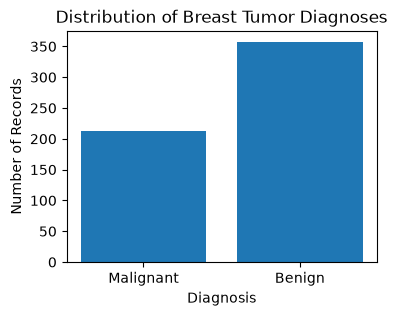

In [18]:
# Create a bar chart showing the diagnosis distribution

diagnosis_counts = df["diagnosis"].value_counts().sort_index()

diagnosis_labels = ["Malignant", "Benign"]

plt.figure(figsize=(4,3))

plt.bar(
    diagnosis_labels,
    diagnosis_counts.values
)

plt.title("Distribution of Breast Tumor Diagnoses")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")

plt.show()

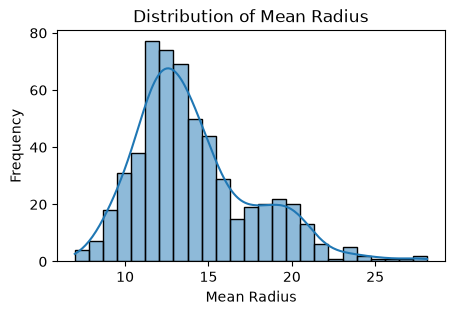

In [20]:
plt.figure(figsize=(5,3))

sns.histplot(
    data=df,
    x="mean radius",
    bins=25,
    kde=True
)

plt.title("Distribution of Mean Radius")
plt.xlabel("Mean Radius")
plt.ylabel("Frequency")

plt.show()

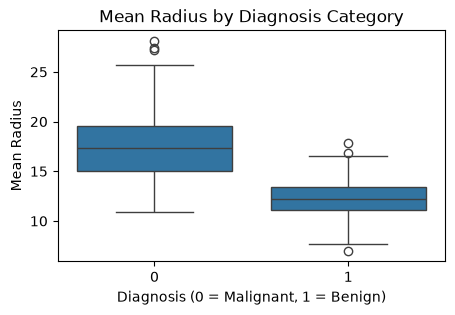

In [23]:
plt.figure(figsize=(5,3))

sns.boxplot(
    data=df,
    x="diagnosis",
    y="mean radius"
)

plt.title("Mean Radius by Diagnosis Category")
plt.xlabel("Diagnosis (0 = Malignant, 1 = Benign)")
plt.ylabel("Mean Radius")

plt.show()

In [24]:
df["diagnosis_label"] = df["diagnosis"].map({
    0: "Malignant",
    1: "Benign"
})

df[["diagnosis", "diagnosis_label"]].head()

,diagnosis,diagnosis_label
0,0,Malignant
1,0,Malignant
2,0,Malignant
3,0,Malignant
4,0,Malignant


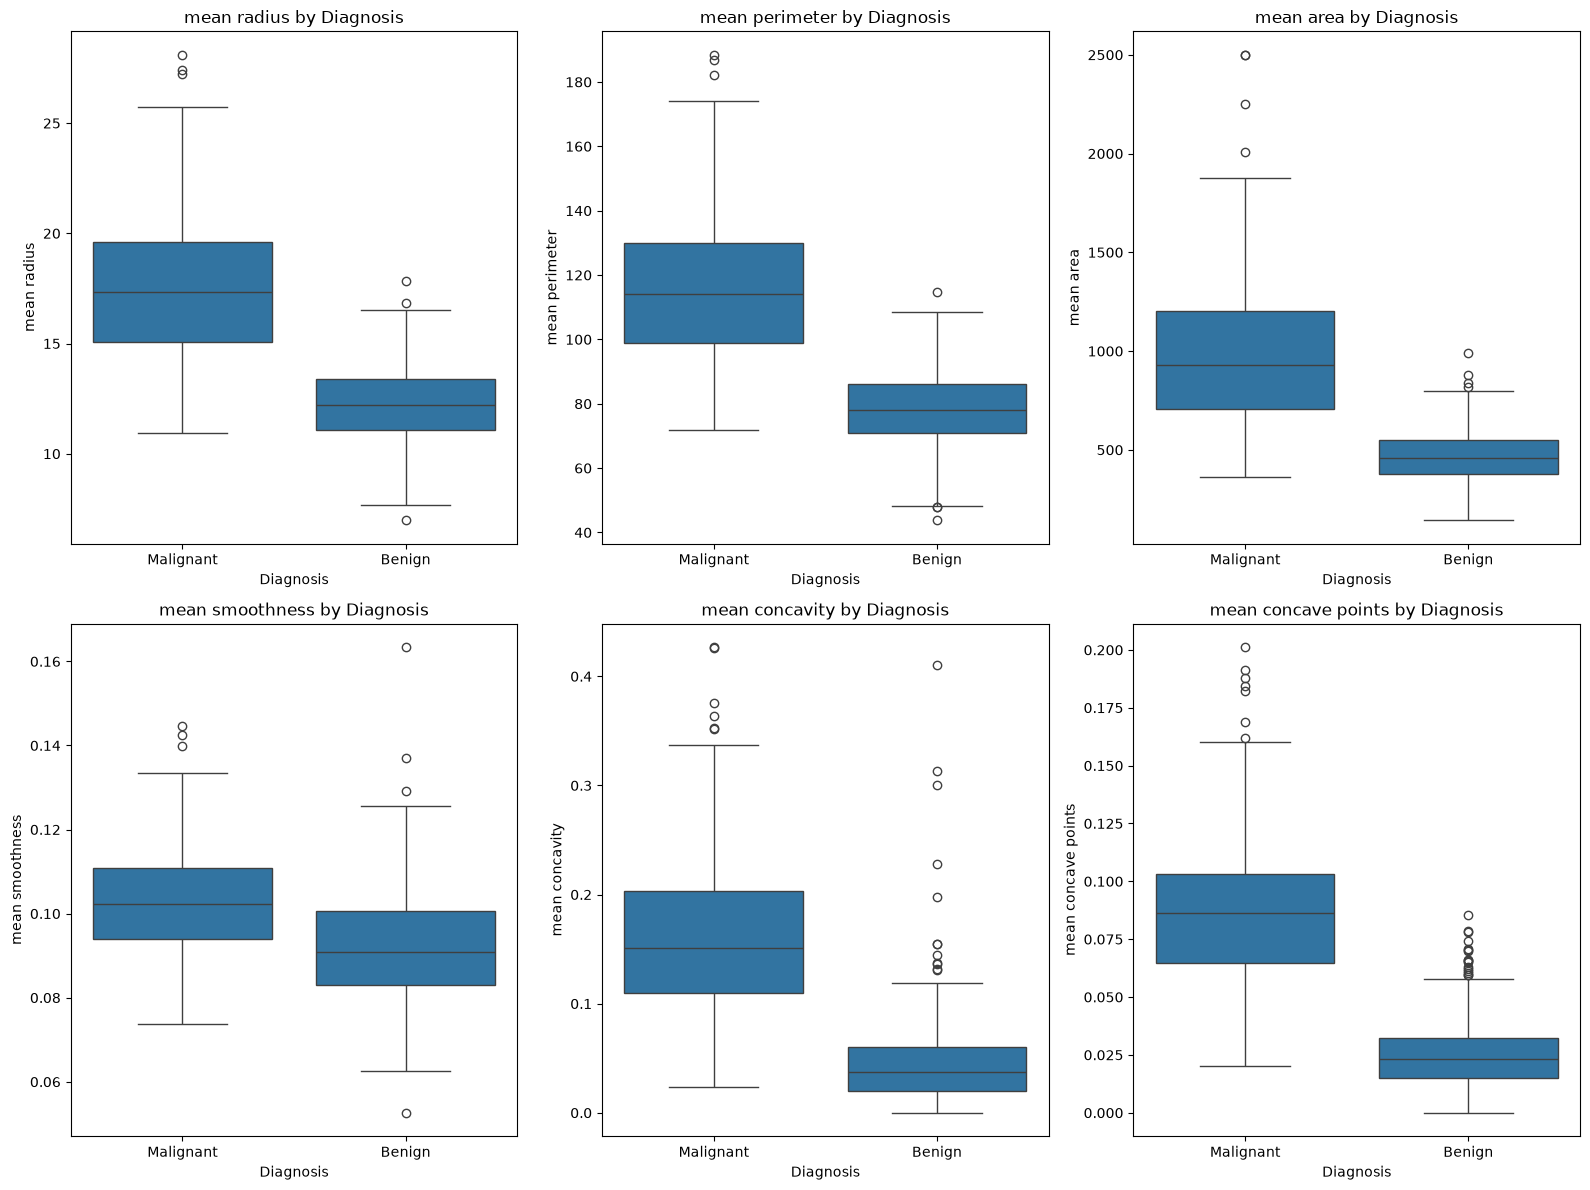

In [25]:
features_to_compare = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean smoothness",
    "mean concavity",
    "mean concave points"
]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features_to_compare, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x="diagnosis_label",
        y=feature
    )

    plt.title(f"{feature} by Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

In [26]:
feature_means = df.groupby("diagnosis_label")[
    features_to_compare
].mean().T

feature_means

diagnosis_label,Benign,Malignant
mean radius,12.146524,17.462830
mean perimeter,78.075406,115.365377
mean area,462.790196,978.376415
mean smoothness,0.092478,0.102898
mean concavity,0.046058,0.160775
mean concave points,0.025717,0.087990


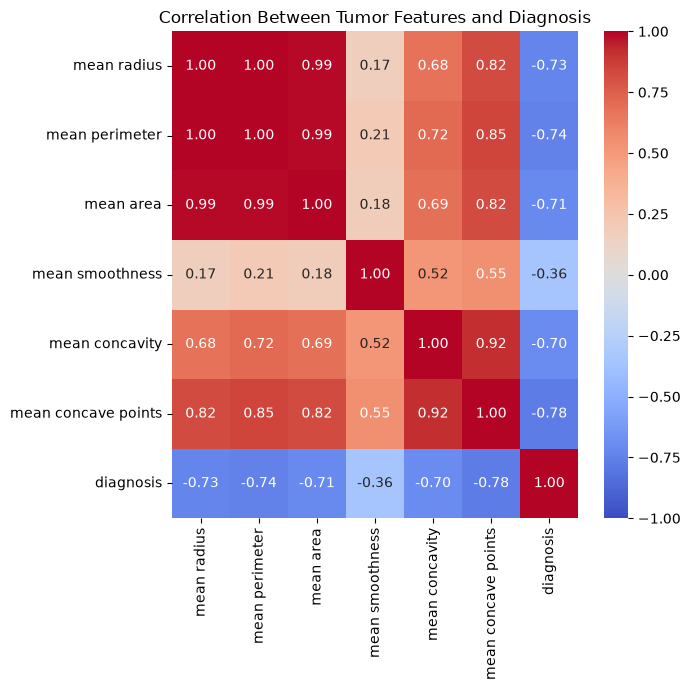

In [30]:
correlation_features = features_to_compare + ["diagnosis"]

correlation_matrix = df[correlation_features].corr()

plt.figure(figsize=(7,7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Tumor Features and Diagnosis")
plt.tight_layout()
plt.show()

In [31]:
feature_correlations = (
    df.drop(columns=["diagnosis_label"])
      .corr()["diagnosis"]
      .drop("diagnosis")
)

feature_ranking = pd.DataFrame({
    "Correlation": feature_correlations,
    "Absolute Correlation": feature_correlations.abs()
})

feature_ranking = feature_ranking.sort_values(
    by="Absolute Correlation",
    ascending=False
)

feature_ranking.head(10)

,Correlation,Absolute Correlation
worst concave points,-0.793566,0.793566
worst perimeter,-0.782914,0.782914
mean concave points,-0.776614,0.776614
worst radius,-0.776454,0.776454
mean perimeter,-0.742636,0.742636
worst area,-0.733825,0.733825
mean radius,-0.730029,0.730029
mean area,-0.708984,0.708984
mean concavity,-0.696360,0.696360
worst concavity,-0.659610,0.659610


Top 5 features by absolute correlation:
['worst concave points', 'worst perimeter', 'mean concave points', 'worst radius', 'mean perimeter']


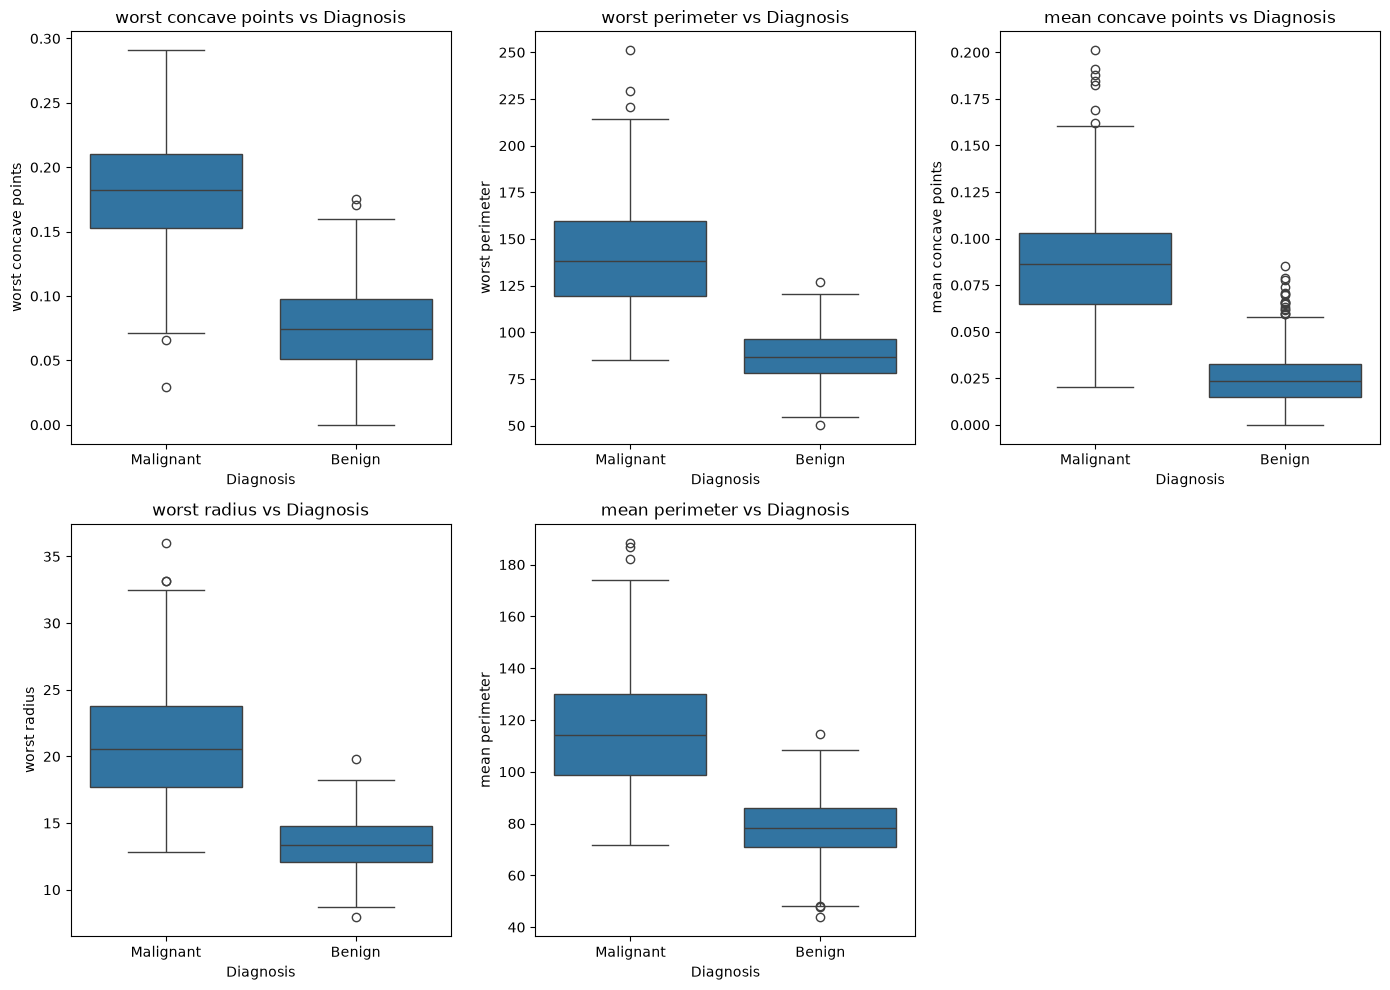

In [32]:
top_5_features = feature_ranking.head(5).index.tolist()

print("Top 5 features by absolute correlation:")
print(top_5_features)

plt.figure(figsize=(14, 10))

for i, feature in enumerate(top_5_features, 1):
    plt.subplot(2, 3, i)

    sns.boxplot(
        data=df,
        x="diagnosis_label",
        y=feature
    )

    plt.title(f"{feature} vs Diagnosis")
    plt.xlabel("Diagnosis")
    plt.ylabel(feature)

plt.tight_layout()
plt.show()

splitting the data

In [33]:
# X contains the input features
# y contains the target diagnosis

X = df.drop(columns=["diagnosis", "diagnosis_label"])
y = df["diagnosis"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget class distribution:")
print(y.value_counts().sort_index())

Features shape: (569, 30)
Target shape: (569,)

Target class distribution:
diagnosis
0    212
1    357
Name: count, dtype: int64


In [36]:
from sklearn.model_selection import train_test_split

# Step 1: Separate input features and output diagnosis
X = df.drop(columns=["diagnosis", "diagnosis_label"])
y = df["diagnosis"]

# Step 2: Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 3: Display the dataset sizes
print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

# Step 4: Check diagnosis distribution in the training set
print("\nTraining diagnosis distribution:")
print(y_train.value_counts().sort_index())

# Step 5: Check diagnosis distribution in the testing set
print("\nTesting diagnosis distribution:")
print(y_test.value_counts().sort_index())


Training set size: (455, 30)
Testing set size: (114, 30)

Training diagnosis distribution:
diagnosis
0    170
1    285
Name: count, dtype: int64

Testing diagnosis distribution:
diagnosis
0    42
1    72
Name: count, dtype: int64


In [38]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Classification libraries imported successfully!")

Classification libraries imported successfully!


In [39]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

print("Three classification models are ready.")

Three classification models are ready.


In [40]:
for model_name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{model_name} trained successfully!")

Logistic Regression trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


check how well the models work

In [41]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [42]:
results = []

for model_name, model in models.items():

    # Predict diagnosis for the test set
    y_pred = model.predict(X_test)

    # Probability of each class
    probabilities = model.predict_proba(X_test)

    # Locate the probability column for malignant cases (class 0)
    malignant_index = list(model.classes_).index(0)
    malignant_probabilities = probabilities[:, malignant_index]

    # Convert the target to 1 = malignant, 0 = benign for ROC-AUC
    y_test_malignant = (y_test == 0).astype(int)

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Specify malignant class (0) explicitly for precision and recall
    precision = precision_score(
        y_test, y_pred, pos_label=0, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, pos_label=0, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, pos_label=0, zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test_malignant,
        malignant_probabilities
    )

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Malignant Precision": precision,
        "Malignant Recall": recall,
        "Malignant F1-Score": f1,
        "Malignant ROC-AUC": roc_auc
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Malignant Recall",
    ascending=False
)

results_df.round(4)

,Model,Accuracy,Malignant Precision,Malignant Recall,Malignant F1-Score,Malignant ROC-AUC
0,Logistic Regression,0.9825,0.9762,0.9762,0.9762,0.9954
1,Decision Tree,0.9211,0.8667,0.9286,0.8966,0.9163
2,Random Forest,0.9561,0.9512,0.9286,0.9398,0.9931


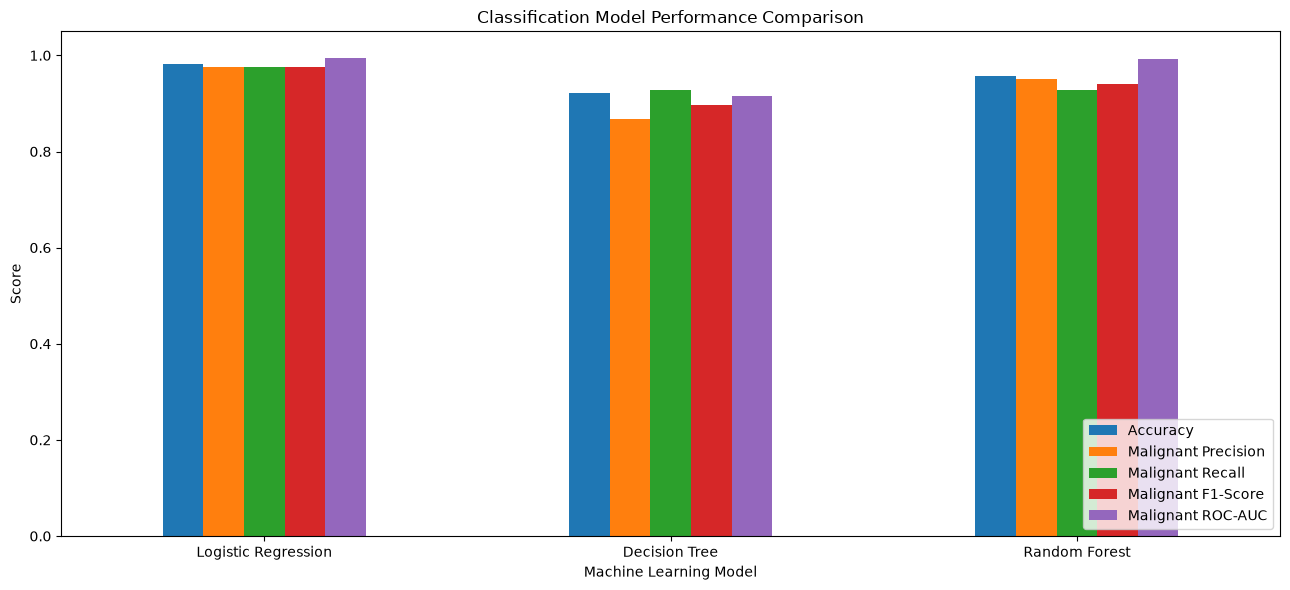

In [43]:
metrics_to_plot = [
    "Accuracy",
    "Malignant Precision",
    "Malignant Recall",
    "Malignant F1-Score",
    "Malignant ROC-AUC"
]

results_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Classification Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Selected model: Logistic Regression


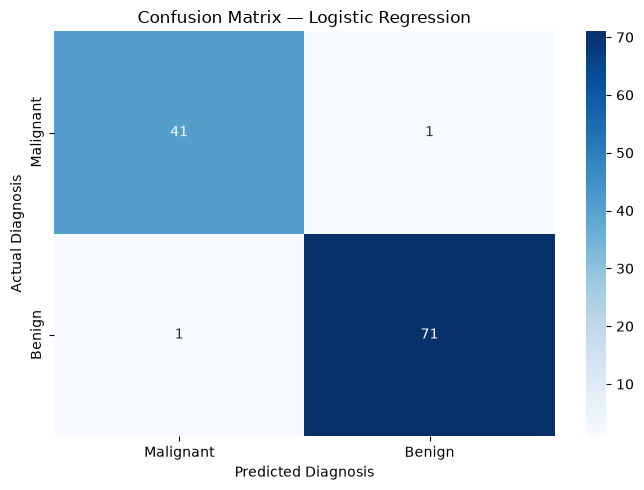

In [44]:
from sklearn.metrics import confusion_matrix

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test)

print("Selected model:", best_model_name)

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted Diagnosis")
plt.ylabel("Actual Diagnosis")
plt.tight_layout()
plt.show()

In [45]:
print("Selected model:", best_model_name)

print(
    classification_report(
        y_test,
        y_pred_best,
        labels=[0, 1],
        target_names=["Malignant", "Benign"],
        zero_division=0
    )
)

Selected model: Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



K-Means Clustering.       This will introduce a second data-mining technique. Unlike classification, clustering doesn't use the diagnosis labels to create groups. Instead, it groups records based on similarities in their numerical features. We'll then compare the resulting clusters with the known diagnoses to explore the patterns.

In [46]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

print("Clustering libraries imported successfully!")

Clustering libraries imported successfully!


In [47]:
# Use the original 30 numerical features
X_clustering = df.drop(columns=["diagnosis", "diagnosis_label"])

# Standardize the features
clustering_scaler = StandardScaler()
X_scaled = clustering_scaler.fit_transform(X_clustering)

print("Original data shape:", X_clustering.shape)
print("Scaled data shape:", X_scaled.shape)

Original data shape: (569, 30)
Scaled data shape: (569, 30)


In [48]:
# Create a K-Means model with two clusters
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign each record to a cluster
cluster_labels = kmeans.fit_predict(X_scaled)

# Store the cluster assignments
df["cluster"] = cluster_labels

print("K-Means clustering completed!")
print("\nNumber of records in each cluster:")
print(df["cluster"].value_counts().sort_index())

K-Means clustering completed!

Number of records in each cluster:
cluster
0    375
1    194
Name: count, dtype: int64


In [49]:
silhouette = silhouette_score(X_scaled, cluster_labels)

print("Silhouette Score:", round(silhouette, 4))

Silhouette Score: 0.3434


In [50]:
cluster_comparison = pd.crosstab(
    df["cluster"],
    df["diagnosis_label"],
    margins=True
)

print("Cluster vs Actual Diagnosis:")
cluster_comparison

Cluster vs Actual Diagnosis:


diagnosis_label,Benign,Malignant,All
cluster,,,
0,339,36,375
1,18,176,194
All,357,212,569


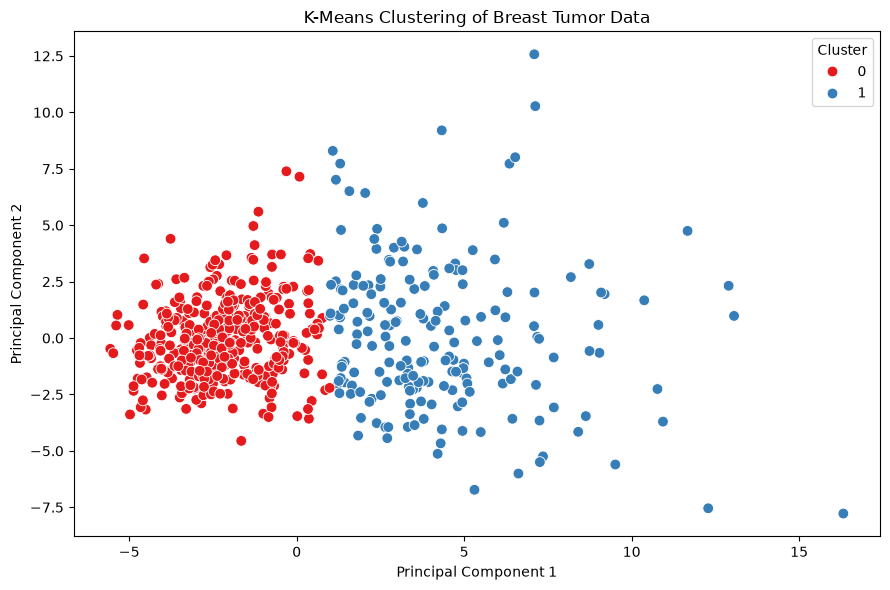

Variance explained by first two components: 63.24 %


In [51]:
from sklearn.decomposition import PCA

# Reduce 30 features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create a dataframe for plotting
pca_df = pd.DataFrame({
    "Principal Component 1": X_pca[:, 0],
    "Principal Component 2": X_pca[:, 1],
    "Cluster": cluster_labels
})

# Plot the clusters
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Cluster",
    palette="Set1",
    s=60
)

plt.title("K-Means Clustering of Breast Tumor Data")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Display how much variance the two components explain
print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

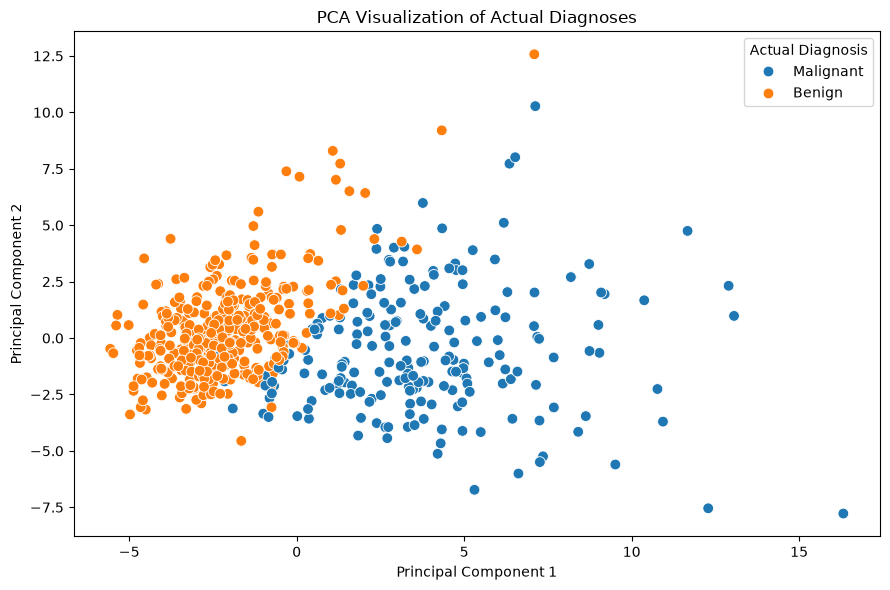

In [52]:
pca_diagnosis_df = pd.DataFrame({
    "Principal Component 1": X_pca[:, 0],
    "Principal Component 2": X_pca[:, 1],
    "Diagnosis": df["diagnosis_label"].values
})

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=pca_diagnosis_df,
    x="Principal Component 1",
    y="Principal Component 2",
    hue="Diagnosis",
    s=60
)

plt.title("PCA Visualization of Actual Diagnoses")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Actual Diagnosis")
plt.tight_layout()
plt.show()

saving the model and the clustering using joblib

In [53]:
import joblib

print("Joblib imported successfully!")

Joblib imported successfully!


In [54]:
model_filename = "breast_cancer_model.joblib"

joblib.dump(best_model, model_filename)

print("Selected model:", best_model_name)
print("Model saved as:", model_filename)

Selected model: Logistic Regression
Model saved as: breast_cancer_model.joblib


In [60]:
import json

feature_names = X.columns.tolist()

with open("feature_names.json", "w") as file:
    json.dump(feature_names, file, indent=2)

print("Feature names saved successfully!")
print("Total features:", len(feature_names))
print(feature_names)

Feature names saved successfully!
Total features: 30
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [55]:
# Calculate the percentage of each diagnosis within each cluster
cluster_percentages = pd.crosstab(
    df["cluster"],
    df["diagnosis_label"],
    normalize="index"
) * 100

print("Diagnosis percentages within each cluster:")
display(cluster_percentages.round(2))

Diagnosis percentages within each cluster:


diagnosis_label,Benign,Malignant
cluster,,
0,90.40,9.60
1,9.28,90.72


In [56]:
import joblib

loaded_model = joblib.load("breast_cancer_model.joblib")

print("Model loaded successfully!")
print("Model type:", type(loaded_model).__name__)

Model loaded successfully!
Model type: Pipeline


In [57]:
# Select one record from the test set
sample = X_test.iloc[[0]]

# Predict its diagnosis
prediction = loaded_model.predict(sample)[0]

# Get the predicted class probabilities
probabilities = loaded_model.predict_proba(sample)[0]

# Map the numeric prediction to a readable label
diagnosis_map = {
    0: "Malignant",
    1: "Benign"
}

print("Predicted class:", diagnosis_map[prediction])

print("\nPredicted class probabilities:")
for class_label, probability in zip(
    loaded_model.classes_,
    probabilities
):
    print(
        f"{diagnosis_map[class_label]}: "
        f"{probability * 100:.2f}%"
    )

Predicted class: Malignant

Predicted class probabilities:
Malignant: 100.00%
Benign: 0.00%


In [58]:
# Get the actual diagnosis for the selected test record
actual_diagnosis = y_test.iloc[0]

# Get the model's prediction
predicted_diagnosis = loaded_model.predict(X_test.iloc[[0]])[0]

# Convert numeric labels to readable names
diagnosis_map = {
    0: "Malignant",
    1: "Benign"
}

print("Actual diagnosis:", diagnosis_map[actual_diagnosis])
print("Predicted diagnosis:", diagnosis_map[predicted_diagnosis])

if actual_diagnosis == predicted_diagnosis:
    print("Prediction matches the dataset label.")
else:
    print("Prediction does not match the dataset label.")

Actual diagnosis: Malignant
Predicted diagnosis: Malignant
Prediction matches the dataset label.


In [59]:
import json

feature_names = X.columns.tolist()

with open("feature_names.json", "w") as file:
    json.dump(feature_names, file, indent=2)

print("Feature names saved successfully!")
print("Total features:", len(feature_names))
print(feature_names)

Feature names saved successfully!
Total features: 30
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [61]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles in this directory:")
print(os.listdir())

Current working directory:
C:\Users\Karwa

Files in this directory:
['-1.14-windows.xml', '.android', '.copilot', '.gemini', '.gitconfig', '.ipynb_checkpoints', '.ipython', '.vscode', '.vscode-shared', '3D Objects', 'AppData', 'Application Data', 'breast_cancer_analysis.ipynb', 'breast_cancer_model.joblib', 'cancer and tumer dataset', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Favorites', 'feature_names.json', 'Links', 'Local Settings', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TM.blf', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000001.regtrans-ms', 'NTUSER.DAT{53b39e88-18c4-11ea-a811-000d3aa4692b}.TMContainer00000000000000000002.regtrans-ms', 'ntuser.ini', 'OneDrive', 'Pictures', 'PrintHood', 'Recent', 'room_equipment_booking', 'Saved Games', 'Searches', 'SendTo', 'Start Menu', 'Templates', 'tour guide.php', 'tour.html', 'tourguide.php', 'ty